# 07 Thực nghiệm kiểm thử Random Agent

**Mục tiêu:** Xác nhận `RandomAgent` chọn đồng đều trên danh sách hành động hợp lệ do Game Engine sinh ra và làm baseline đối chứng trung thực.

**Giả thuyết cần kiểm chứng:**
- **H1:** Mọi hành động được chọn đều nằm trong `legal_actions` hợp lệ từ Game Engine.
- **H2:** Cùng `seed` và cùng chuỗi trạng thái đầu vào cho kết quả hoàn toàn tái lập được.
- **H3:** Trên một trạng thái cố định, phân phối lựa chọn tiệm cận phân phối đều trên các hành động hợp lệ (không đồng nhất với xác suất đều theo *quân cờ*).
- **H4:** Quá trình suy luận của Agent không làm thay đổi `GameState` hoặc `legal_actions` đầu vào.

## I. Import thư viện

In [1]:
from pathlib import Path
import sys

_cwd = Path.cwd().resolve()
_exp_dir = next(
    (p / "research" / "experiments" for p in (_cwd, *_cwd.parents) if (p / "research" / "experiments" / "common").is_dir()),
    _cwd if (_cwd / "common").is_dir() else None,
)
if _exp_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục `research/experiments/common`.")
if str(_exp_dir) not in sys.path:
    sys.path.insert(0, str(_exp_dir))

from scipy.stats import chisquare

from common.imports import *
from common import (
    ExperimentLogger,
    ProfileScope,
    bootstrap_confidence_interval,
    capture_memory_snapshot,
    compute_state_hash,
    create_agent,
    finish_wandb_run,
    format_action_str,
    get_environment_info,
    get_git_revision,
    init_wandb_run,
    load_experiment_config,
    log_wandb_metrics,
    log_wandb_table,
    plot_decision_time_comparison,
    plot_metric_bar,
    plot_turn_length_distribution,
    plot_wdl_stacked_bar,
    run_head_to_head,
    run_match,
    set_global_seed,
    summarize_agent_matches,
    summarize_pair_results,
    summarize_red_blue_splits,
    wilson_confidence_interval,
)

env_info = get_environment_info()
git_info = get_git_revision()
try:
    from IPython.display import display
except ImportError:
    display = print
load_dotenv(PROJECT_ROOT / ".env")
try:
    wandb_api_key_ready = bool(os.environ.get("WANDB_API_KEY"))
    if not wandb_api_key_ready and HAS_WANDB and wandb is not None:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            wandb_api_key_ready = bool(getattr(getattr(wandb, "api", None), "api_key", None))
except Exception:
    wandb_api_key_ready = False
print(f"Python {env_info['python_version']} | CPU cores: {env_info['cpu_count']} | Git: {git_info}")
print("W&B installed:", HAS_WANDB, "| W&B API key configured:", wandb_api_key_ready)


d:\Commander-Chess-AI\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
wandb: WARNING wandb.api and wandb.ensure_configured() are deprecated and will be removed in a future release. To check for credentials without prompting, use wandb.login(prompt=False).


Python 3.10.0 | CPU cores: 16 | Git: {'commit': '4fba4327ef3eac24134123b137af0e69d80caaaa', 'branch': 'main', 'is_dirty': True}
W&B installed: True | W&B API key configured: True


## II. Cấu hình thực nghiệm

In [2]:
cfg = load_experiment_config("07_test_random_agent")

# Tùy chỉnh điều khiển chạy notebook (tuần tự 07 -> 08 -> 09)
USE_WANDB = True
WANDB_MODE = "online"            # "online" | "offline" | "disabled"
RUN_OPPONENT_COMPARISONS = False # Mặc định False ở bước 07 (chỉ chạy Random vs Random); bật True sau khi 08/09 xong
RUN_CONTROLLED_BUDGET = True     # Chạy thêm Chế độ B (move_timeout_ms = 1000, strict_timeout = True)
MAX_WORKERS = max(1, min(8, (os.cpu_count() or 2) // 2))

UNIFORMITY_SAMPLES = int(cfg.get("uniformity_samples", 1000))
GAMES_PER_PAIR = int(cfg["games_per_pair"])
MAX_TURNS = int(cfg["max_turns"])
DRAW_ON_MAX_TURNS = bool(cfg.get("draw_on_max_turns", False))
SEEDS = list(cfg["seeds"])
RUN_ID = f"rnd_{datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')}"

set_global_seed(cfg["seed"])

print(f"Experiment ID     : {cfg['experiment_id']}")
print(f"Run ID            : {RUN_ID}")
print(f"Games per pair    : {GAMES_PER_PAIR} (side_balance={cfg['side_balance']})")
print(f"Max turns / Draw  : {MAX_TURNS} / draw_on_max_turns={DRAW_ON_MAX_TURNS}")
print(f"Seeds ({len(SEEDS)})         : {SEEDS}")
print(f"Budget modes      : {list(cfg['budget_modes'].keys())}")
print(f"Output dir        : {cfg['resolved_output_dir']}")
print(f"W&B dir           : {cfg['resolved_wandb_dir']} (use_wandb={USE_WANDB}, mode={WANDB_MODE})")
print(f"Parallel workers  : {MAX_WORKERS}")


Experiment ID     : 07_test_random_agent
Run ID            : rnd_20261111T040751Z
Games per pair    : 200 (side_balance=True)
Max turns / Draw  : 200 / draw_on_max_turns=False
Seeds (10)         : [2026, 42, 0, 7, 123, 1337, 2024, 2025, 3407, 9999]
Budget modes      : ['default', 'controlled']
Output dir        : D:\Commander-Chess-AI\research\results\07_test_random_agent
W&B dir           : D:\Commander-Chess-AI\research\runs (use_wandb=True, mode=online)
Parallel workers  : 8


## III. Khởi tạo môi trường và Agent

In [3]:
init_state = create_initial_state()
legal_actions = generate_legal_actions(init_state)

random_agent = create_agent(
    "random",
    config=cfg["agent_configs"]["random"],
    seed=cfg["seed"],
    instance_name="random",
)

smoke_decision = random_agent.select_action(init_state, legal_actions)
print(f"Initial state hash : {compute_state_hash(init_state)}")
print(f"Legal actions count: {len(legal_actions)}")
print(f"Sample decision    : {format_action_str(smoke_decision.action)}")
print("Agent metadata     :", smoke_decision.metadata)
print("Memory snapshot    :", capture_memory_snapshot())


Initial state hash : 2849d263040ff8d6
Legal actions count: 114
Sample decision    : BOARD:red_aircraft_1@(1,4)->(1,1)#target=red_navy_1#carrier=red_navy_1
Agent metadata     : {'agent_name': 'random', 'algorithm': 'random', 'version': '1.0.0', 'seed': 2026, 'decision_time_ms': 0.004599998646881431, 'candidates_count': 114}
Memory snapshot    : {'process_rss_mb': 223.68359375, 'cpu_count': 16, 'process_cpu_percent': 0.0, 'vram_available': False, 'vram_allocated_mb': None, 'vram_reserved_mb': None}


## IV. Kiểm thử chức năng

In [4]:
unit_records: list[dict[str, Any]] = []


def _record_test(name: str, passed: bool, detail: str) -> None:
    unit_records.append({"test": name, "passed": bool(passed), "detail": detail})
    assert passed, f"[{name}] Thất bại: {detail}"


# 4.1. Legal action qua 50 trạng thái ngẫu nhiên
sampler = RandomAgent(name="sampler", seed=cfg["seed"])
cur_state = create_initial_state()
checked_states = 0
for _ in range(50):
    legal = generate_legal_actions(cur_state)
    if not legal:
        break
    dec = sampler.select_action(cur_state, legal)
    assert dec.action in legal
    cur_state = apply_action(cur_state, dec.action).state
    checked_states += 1
_record_test("4.1 Legal action", checked_states > 0, f"Kiểm tra {checked_states} bước hợp lệ liên tiếp.")

# 4.2. Empty / terminal state
empty_raised = False
try:
    sampler.select_action(init_state, [])
except NoLegalActionsError:
    empty_raised = True
_record_test("4.2 Empty/terminal state", empty_raised, "Raise NoLegalActionsError khi danh sách nước rỗng.")

# 4.3. Không đột biến GameState và legal_actions đầu vào
state_copy = deepcopy(init_state)
legal_before = list(legal_actions)
hash_before = compute_state_hash(init_state)
_ = create_agent("random", seed=77).select_action(init_state, legal_actions)
no_mutation = (
    compute_state_hash(init_state) == hash_before
    and legal_actions == legal_before
    and len(init_state.pieces) == len(state_copy.pieces)
)
_record_test("4.3 Non-mutation", no_mutation, "State hash và legal_actions giữ nguyên sau select_action.")

# 4.4. Seed reproducibility
a1 = create_agent("random", seed=999)
a2 = create_agent("random", seed=999)
seq1 = [a1.select_action(init_state, legal_actions).action for _ in range(25)]
seq2 = [a2.select_action(init_state, legal_actions).action for _ in range(25)]
_record_test("4.4 Seed reproducibility", seq1 == seq2, "25 lượt cùng seed=999 khớp nhau 100%.")

# 4.5. Uniform distribution trên trạng thái cố định
n_actions = len(legal_actions)
n_samples = max(UNIFORMITY_SAMPLES, n_actions * 20)
probe_agent = create_agent("random", seed=cfg["seed"])
counts = Counter(
    format_action_str(probe_agent.select_action(init_state, legal_actions).action)
    for _ in range(n_samples)
)
all_labels = [format_action_str(a) for a in legal_actions]
obs_freq = np.array([counts[lbl] for lbl in all_labels], dtype=float)
exp_freq = np.full(n_actions, n_samples / n_actions, dtype=float)
chi2_stat, chi2_pvalue = chisquare(obs_freq, f_exp=exp_freq)
uniform_ok = bool(chi2_pvalue > 0.01)
uniformity_report = {
    "seed": cfg["seed"],
    "state_hash": compute_state_hash(init_state),
    "n_actions": int(n_actions),
    "n_samples": int(n_samples),
    "expected_freq_per_action": float(n_samples / n_actions),
    "min_observed_freq": int(obs_freq.min()),
    "max_observed_freq": int(obs_freq.max()),
    "std_observed_freq": float(np.std(obs_freq)),
    "chi2_statistic": float(chi2_stat),
    "chi2_pvalue": float(chi2_pvalue),
    "alpha": 0.05,
    "passed": bool(chi2_pvalue > 0.05),
    "action_frequencies": {lbl: int(counts[lbl]) for lbl in all_labels},
}
_record_test(
    "4.5 Uniform distribution",
    uniform_ok,
    f"N={n_samples}, K={n_actions}, E={n_samples / n_actions:.2f}, chi2={chi2_stat:.2f}, p={chi2_pvalue:.4f}",
)

# 4.6. Compound action: hỗ trợ triển khai quân cõng và END_TURN
ct_board = GameState(
    board=Board(),
    pieces={
        p.id: p
        for p in [
            Piece("red_cmd", PieceType.COMMANDER, Player.RED, (0, 2)),
            Piece("red_tank_1", PieceType.TANK, Player.RED, (4, 5), cargo=["red_inf_1"]),
            Piece("red_inf_1", PieceType.INFANTRY, Player.RED, None, carried_by="red_tank_1"),
            Piece("blue_cmd", PieceType.COMMANDER, Player.BLUE, (11, 6)),
        ]
    },
    current_player=Player.RED,
)
ct_board.validate_structure()
deploy_action = next(
    a for a in generate_legal_actions(ct_board)
    if not isinstance(a, TurnCommand) and a.piece_id == "red_inf_1"
)
after_deploy = apply_action(ct_board, deploy_action).state
ct_legal = generate_legal_actions(after_deploy)
has_end_turn = any(isinstance(a, TurnCommand) and a.command_type == TurnCommandType.END_TURN for a in ct_legal)
sampled_ct_types = {
    a.command_type.value if isinstance(a, TurnCommand) else a.action_type.value
    for a in (RandomAgent(seed=10 + i).select_action(after_deploy, ct_legal).action for i in range(60))
}
_record_test(
    "4.6 Compound action",
    has_end_turn and ("end_turn" in sampled_ct_types),
    f"Loại hành động tổ hợp chọn được: {sorted(sampled_ct_types)}",
)

# 4.7. Full-game invariant across 5 games
invariant_steps = 0
for g_idx in range(5):
    g_state = create_initial_state()
    r_red = RandomAgent(name="inv_r", seed=cfg["seed"] + g_idx)
    r_blue = RandomAgent(name="inv_b", seed=cfg["seed"] + 1000 + g_idx)
    while g_state.game_status == GameStatus.ONGOING and g_state.turn_number <= 30:
        g_legal = generate_legal_actions(g_state)
        if not g_legal:
            break
        cur_p = g_state.current_player
        act = (r_red if cur_p == Player.RED else r_blue).select_action(g_state, g_legal).action
        assert act in g_legal
        res = apply_action(g_state, act)
        assert res.accepted
        res.state.validate_structure()
        assert len(res.state.pieces) <= len(g_state.pieces)
        g_state = res.state
        invariant_steps += 1
_record_test("4.7 Full-game invariant", invariant_steps > 50, f"Xác thực cấu trúc hợp lệ qua {invariant_steps} quyết định.")

test_results_df = pd.DataFrame(unit_records)
display(test_results_df)


,test,passed,detail
0,4.1 Legal action,True,Kiểm tra 50 bước hợp lệ liên tiếp.
1,4.2 Empty/terminal state,True,Raise NoLegalActionsError khi danh sách nước r...
2,4.3 Non-mutation,True,State hash và legal_actions giữ nguyên sau sel...
3,4.4 Seed reproducibility,True,25 lượt cùng seed=999 khớp nhau 100%.
4,4.5 Uniform distribution,True,"N=2280, K=114, E=20.00, chi2=133.80, p=0.0884"
5,4.6 Compound action,True,"Loại hành động tổ hợp chọn được: ['end_turn', ..."
6,4.7 Full-game invariant,True,Xác thực cấu trúc hợp lệ qua 155 quyết định.


## V. Chạy thực nghiệm

In [5]:
# 5.1. Debug một ván Random vs Random để kiểm tra kết thúc & biên bản
debug_match = run_match(
    create_agent("random", seed=cfg["seed"], instance_name="random_red"),
    create_agent("random", seed=cfg["seed"] + 10000, instance_name="random_blue"),
    seed=cfg["seed"],
    max_turns=MAX_TURNS,
    draw_on_max_turns=DRAW_ON_MAX_TURNS,
    run_id=f"{RUN_ID}_debug",
    budget_mode="default",
    match_id="debug_rnd_vs_rnd_0001",
)
print(
    f"[Debug 1 ván] status={debug_match.result_status}, winner={debug_match.winner}, "
    f"reason={debug_match.reason}, turns={debug_match.turn_count}, "
    f"decisions={debug_match.total_decisions}, atomic={debug_match.total_atomic_actions}, "
    f"duration={debug_match.duration_sec:.2f}s"
)

# 5.2 & 5.3. Thực nghiệm chính theo 2 chế độ ngân sách (A: default, B: controlled 1000ms)
modes_to_run = ["default", "controlled"] if RUN_CONTROLLED_BUDGET else ["default"]
pair_specs = [("random", "random", "random", "random")]
if RUN_OPPONENT_COMPARISONS:
    pair_specs.extend([
        ("random", "rules", "random", "rules"),
        ("random", "heuristic", "random", "heuristic"),
    ])

all_matches: list[Any] = []
pair_tables: list[pd.DataFrame] = []
red_blue_tables: list[pd.DataFrame] = []

wb_run = None
if USE_WANDB and WANDB_MODE != "disabled":
    if getattr(wandb, "run", None) is not None:
        finish_wandb_run(wandb.run)
    wb_run = init_wandb_run(
        cfg,
        project=cfg.get("wandb_project", "commander-chess-ai"),
        name=f"07_random_{RUN_ID}",
        group=cfg.get("wandb_group", "random-agent"),
        job_type="baseline-benchmark",
        tags=["random", "baseline", *modes_to_run],
        mode=WANDB_MODE,
        enabled=USE_WANDB,
    )

try:
    with ProfileScope("07_random_experiment") as prof:
        for mode_name in modes_to_run:
            b_cfg = cfg["budget_modes"][mode_name]
            for a_key, b_key, a_lbl, b_lbl in pair_specs:
                matches = run_head_to_head(
                    a_key,
                    b_key,
                    games_per_pair=GAMES_PER_PAIR,
                    side_balance=bool(cfg["side_balance"]),
                    seeds=SEEDS,
                    max_turns=MAX_TURNS,
                    budget_mode=mode_name,
                    move_timeout_ms=b_cfg.get("move_timeout_ms"),
                    strict_timeout=bool(b_cfg.get("strict_timeout", False)),
                    draw_on_max_turns=DRAW_ON_MAX_TURNS,
                    agent_configs=cfg["agent_configs"],
                    agent_a_label=a_lbl,
                    agent_b_label=b_lbl,
                    record_moves=True,
                    run_id=RUN_ID,
                    show_progress=True,
                    max_workers=MAX_WORKERS,
                )
                all_matches.extend(matches)
                p_df = summarize_pair_results(
                    matches,
                    run_id=RUN_ID,
                    agent_a=a_lbl,
                    agent_b=b_lbl,
                    budget_mode=mode_name,
                    seed=cfg["seed"],
                )
                pair_tables.append(p_df)

                rb_df = summarize_red_blue_splits(a_lbl, matches)
                rb_df["opponent"] = b_lbl
                rb_df["budget_mode"] = mode_name
                red_blue_tables.append(rb_df)

    pair_results_df = pd.concat(pair_tables, ignore_index=True)
    red_blue_df = pd.concat(red_blue_tables, ignore_index=True) if red_blue_tables else pd.DataFrame()
    exp_prof = prof.result
    print(f"Hoàn tất {len(all_matches)} ván trong {exp_prof.wall_time_ms / 1000.0:.2f}s (Peak Python RAM={exp_prof.python_peak_ram_mb:.2f} MB)")
    display(pair_results_df)
    if not red_blue_df.empty:
        display(red_blue_df)

    if wb_run is not None:
        log_wandb_metrics(
            wb_run,
            {
                "uniformity/chi2_pvalue": uniformity_report["chi2_pvalue"],
                "uniformity/n_samples": uniformity_report["n_samples"],
                "performance/total_experiment_sec": exp_prof.wall_time_ms / 1000.0,
                "performance/peak_ram_mb": exp_prof.process_rss_after_mb or exp_prof.python_peak_ram_mb,
            },
        )
        log_wandb_table(wb_run, "pair_results", pair_results_df)
        if not red_blue_df.empty:
            log_wandb_table(wb_run, "red_blue_splits", red_blue_df)
finally:
    finish_wandb_run(wb_run)


wandb: [wandb.login()] Loaded credentials for https://api.forge.coreweave.com from C:\Users\ACER\_netrc.


[Debug 1 ván] status=truncated, winner=None, reason=MAX_MOVES_EXCEEDED, turns=201, decisions=209, atomic=206, duration=7.96s


wandb: Currently logged in as: ngodongat2005 (ngodongat2005-st-george-s-university) to https://api.forge.coreweave.com. Use `wandb login --relogin` to force relogin
--- Logging error ---
Traceback (most recent call last):
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\logging\__init__.py", line 1101, in emit
    stream.write(msg + self.terminator)
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\encodings\cp1252.py", line 19, in encode
    return codecs.charmap_encode(input,self.errors,encoding_table)[0]
UnicodeEncodeError: 'charmap' codec can't encode character '\u1ebf' in position 494: character maps to <undefined>
Call stack:
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 196, in _run_module_as_main
    return _run_code(code, main_globals, None,
  File "C:\Users\ACER\AppData\Local\Programs\Python\Python310\lib\runpy.py", line 86, in _run_code
    exec(code, run_globals)
  File "d:\Commander-Chess-AI\.venv\lib\sit

wandb: Detected [agents] in use.
wandb: Use W&B Weave for improved LLM call tracing. Install Weave with `pip install weave` then add `import weave` to the top of your script.
wandb: For more information, check out the docs at: https://weave-docs.wandb.ai
random vs random [controlled]: 100%|██████████| 200/200 [24:55<00:00,  7.48s/it]   


Hoàn tất 400 ván trong 1932.82s (Peak Python RAM=89.87 MB)


,run_id,agent_a,agent_b,budget_mode,total_games,games_completed,truncated_games,timeout_games,error_games,wins_a,...,ci_method,bootstrap_resamples,mean_decision_ms_a,p95_decision_ms_a,mean_decision_ms_b,p95_decision_ms_b,avg_turns,avg_decisions,budget_exceeded_a,budget_exceeded_b
0,rnd_20261111T040751Z,random,random,default,200,12,188,0,0,6,...,paired_cluster_bootstrap+wilson,2000,0.006328,0.0078,0.006586,0.0078,196.57,201.63,0,0
1,rnd_20261111T040751Z,random,random,controlled,200,12,188,0,0,6,...,paired_cluster_bootstrap+wilson,2000,0.007493,0.0077,0.007243,0.0078,196.57,201.63,0,0


,agent,side,total_games,completed_games,truncated_games,wins,draws,losses,win_rate,draw_rate,loss_rate,score_ratio,win_rate_ci_low,win_rate_ci_high,avg_decision_time_ms,p95_decision_time_ms,opponent,budget_mode
0,random,red,200,12,188,6,0,6,0.5,0.0,0.5,0.5,0.253782,0.746218,0.006487,0.0078,random,default
1,random,blue,200,12,188,6,0,6,0.5,0.0,0.5,0.5,0.253782,0.746218,0.006427,0.0078,random,default
2,random,red,200,12,188,6,0,6,0.5,0.0,0.5,0.5,0.253782,0.746218,0.007424,0.0078,random,controlled
3,random,blue,200,12,188,6,0,6,0.5,0.0,0.5,0.5,0.253782,0.746218,0.007312,0.0077,random,controlled


wandb: ERROR The nbformat package was not found. It is required to save notebook history.


performance/peak_ram_mb,▁
performance/total_experiment_sec,▁
uniformity/chi2_pvalue,▁
uniformity/n_samples,▁
performance/peak_ram_mb,333.63672
performance/total_experiment_sec,1932.8239
uniformity/chi2_pvalue,0.08843
uniformity/n_samples,2280


## VI. Thu thập dữ liệu

In [6]:
logger = ExperimentLogger.from_config(cfg, run_tag=RUN_ID)
logger.save_config_json(cfg)
logger.save_environment_json(
    cfg,
    extra={
        "run_id": RUN_ID,
        "wandb_run_id": getattr(wb_run, "id", None),
        "profile_wall_sec": round(exp_prof.wall_time_ms / 1000.0, 3),
    },
)
logger.save_json("uniformity_test.json", uniformity_report)

# Lưu biên bản từng ván trước khi ghi games.csv để gắn đúng game_record_path
logger.save_game_records(all_matches, run_id=RUN_ID)
games_csv_path = logger.save_games_csv(all_matches, run_id=RUN_ID)
moves_csv_path = logger.save_moves_csv(all_matches, run_id=RUN_ID)
pairs_csv_path = logger.save_pair_results_csv(pair_results_df)
if not red_blue_df.empty:
    logger.save_csv("red_blue_splits.csv", red_blue_df)

# Kiểm tra chất lượng log xuất ra
games_df = pd.read_csv(games_csv_path)
moves_df = pd.read_csv(moves_csv_path, keep_default_na=True, low_memory=False)

assert moves_df["nodes_visited"].isna().all(), "Random/Rules/Heuristic không được ghi nodes_visited=0!"
assert moves_df["simulations"].isna().all(), "Random/Rules/Heuristic không được ghi simulations=0!"

status_counts = games_df.groupby(["budget_mode", "result_status"]).size().rename("count").reset_index()
print(f"Đã xuất toàn bộ kết quả tại: {logger.run_dir}")
display(status_counts)


Đã xuất toàn bộ kết quả tại: D:\Commander-Chess-AI\research\results\07_test_random_agent\rnd_20261111T040751Z


,budget_mode,result_status,count
0,controlled,completed,12
1,controlled,truncated,188
2,default,completed,12
3,default,truncated,188


## VII. Trực quan hóa kết quả

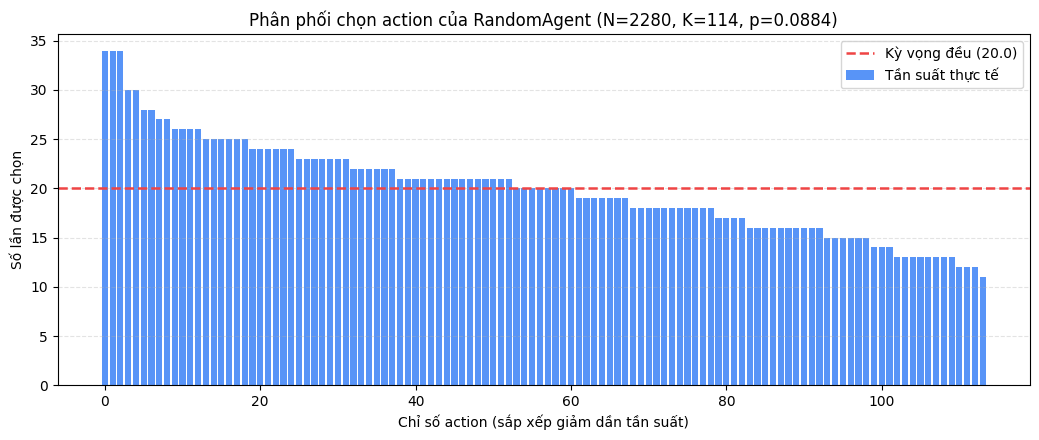

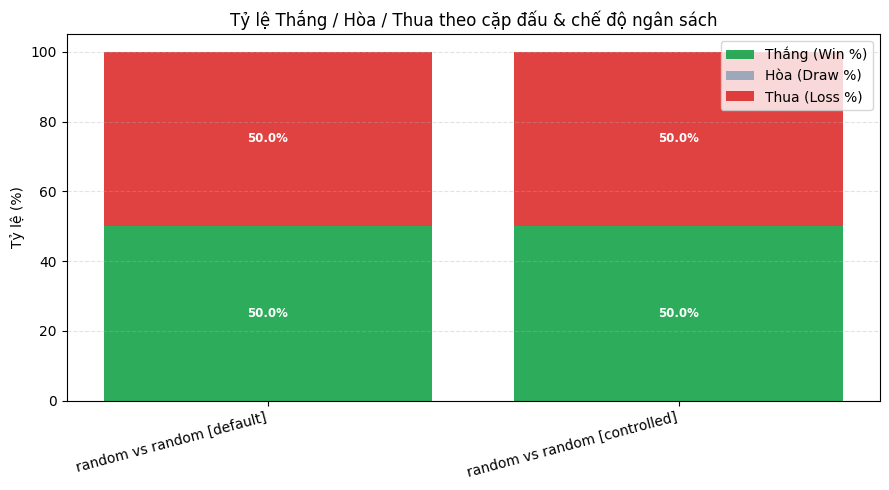

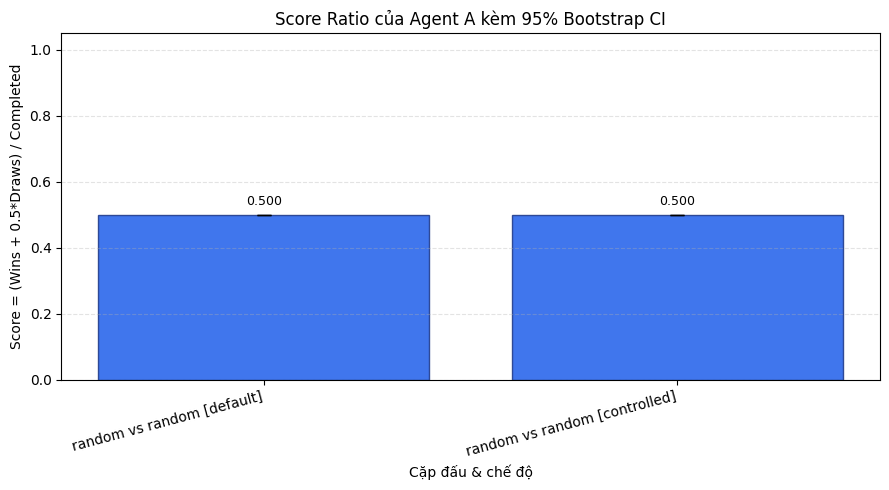

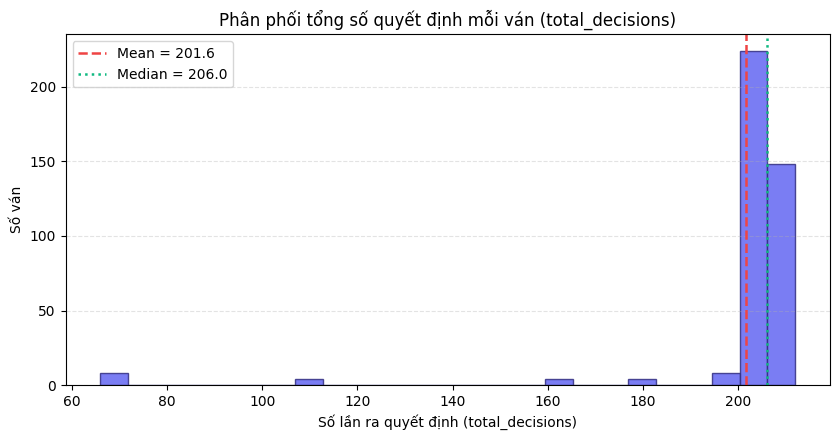

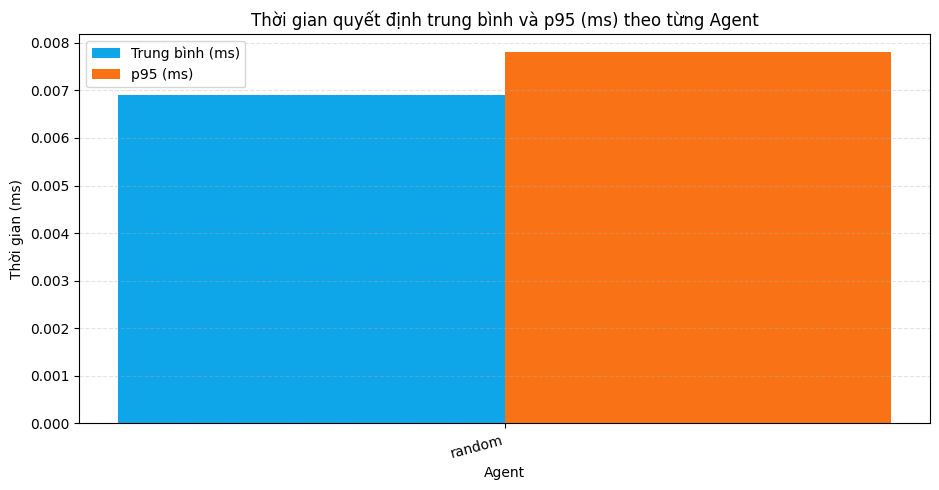

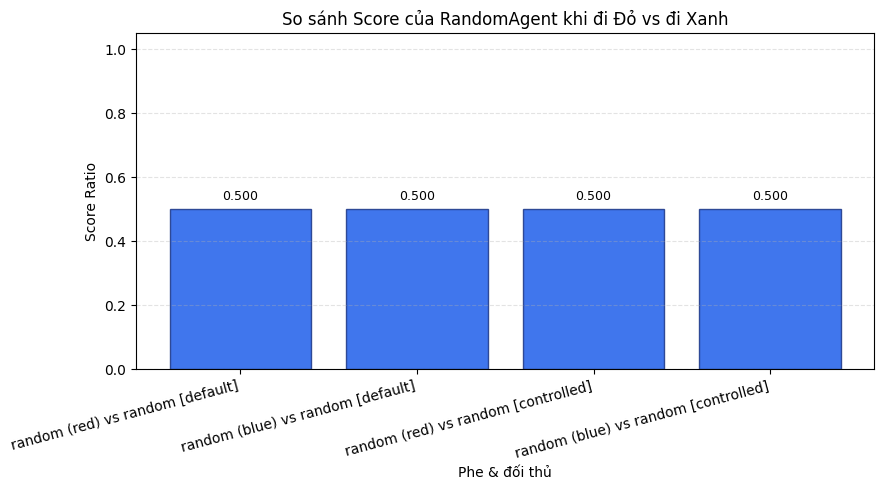

In [7]:
figures_dir = logger.run_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

# 1. Phân phối lựa chọn từng action ở trạng thái ban đầu (Uniformity Test)
fig_uni, ax_uni = plt.subplots(figsize=(10.5, 4.5))
sorted_counts = np.sort(obs_freq)[::-1]
ax_uni.bar(np.arange(len(sorted_counts)), sorted_counts, color="#3b82f6", alpha=0.85, label="Tần suất thực tế")
ax_uni.axhline(n_samples / n_actions, color="#ef4444", linestyle="--", linewidth=1.8, label=f"Kỳ vọng đều ({n_samples / n_actions:.1f})")
ax_uni.set_title(f"Phân phối chọn action của RandomAgent (N={n_samples}, K={n_actions}, p={chi2_pvalue:.4f})")
ax_uni.set_xlabel("Chỉ số action (sắp xếp giảm dần tần suất)")
ax_uni.set_ylabel("Số lần được chọn")
ax_uni.legend()
ax_uni.grid(axis="y", linestyle="--", alpha=0.35)
fig_uni.tight_layout()
fig_uni.savefig(figures_dir / "fig_01_uniformity_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

# 2. Biểu đồ W/D/L và Score kèm 95% Bootstrap CI
plot_df = pair_results_df.copy()
plot_df["pair_label"] = plot_df["agent_a"] + " vs " + plot_df["agent_b"] + " [" + plot_df["budget_mode"] + "]"
plot_wdl_stacked_bar(
    plot_df,
    label_col="pair_label",
    win_col="win_rate_a",
    draw_col="draw_rate",
    loss_col="loss_rate_a",
    title="Tỷ lệ Thắng / Hòa / Thua theo cặp đấu & chế độ ngân sách",
    save_path=figures_dir / "fig_02_wdl_rates.png",
)
plt.show()

plot_metric_bar(
    plot_df,
    label_col="pair_label",
    metric_col="score_a",
    ci_low_col="score_ci_low",
    ci_high_col="score_ci_high",
    title="Score Ratio của Agent A kèm 95% Bootstrap CI",
    xlabel="Cặp đấu & chế độ",
    ylabel="Score = (Wins + 0.5*Draws) / Completed",
    save_path=figures_dir / "fig_03_score_ci.png",
)
plt.show()

# 3. Phân phối độ dài ván đấu & thời gian quyết định mean/p95
plot_turn_length_distribution(
    games_df["total_decisions"].tolist(),
    title="Phân phối tổng số quyết định mỗi ván (total_decisions)",
    xlabel="Số lần ra quyết định (total_decisions)",
    save_path=figures_dir / "fig_04_game_length_dist.png",
)
plt.show()

if not moves_df.empty:
    latency_rows = (
        moves_df.groupby("agent_name")["decision_time_ms"]
        .agg(
            avg_decision_time_ms="mean",
            p95_decision_time_ms=lambda s: float(np.percentile(s, 95)),
        )
        .reset_index()
        .rename(columns={"agent_name": "agent"})
    )
    plot_decision_time_comparison(
        latency_rows,
        title="Thời gian quyết định trung bình và p95 (ms) theo từng Agent",
        save_path=figures_dir / "fig_05_latency_comparison.png",
    )
    plt.show()

# 4. So sánh hiệu năng theo phe Đỏ (đi trước) vs Xanh (đi sau)
if not red_blue_df.empty:
    rb_plot = red_blue_df.copy()
    rb_plot["label"] = rb_plot["agent"] + " (" + rb_plot["side"] + ") vs " + rb_plot["opponent"] + " [" + rb_plot["budget_mode"] + "]"
    plot_metric_bar(
        rb_plot,
        label_col="label",
        metric_col="score_ratio",
        title="So sánh Score của RandomAgent khi đi Đỏ vs đi Xanh",
        xlabel="Phe & đối thủ",
        ylabel="Score Ratio",
        save_path=figures_dir / "fig_06_red_blue_split.png",
    )
    plt.show()


## VIII. Nhận xét và kết luận

*(Điền trực tiếp từ số liệu đã chạy ở Mục IV–VII, không suy đoán hay dùng số mẫu)*

1. **Kiểm chứng giả thuyết H1–H4:**
   - **H1 (Hợp lệ):** `test_results_df` xác nhận mọi hành động trả về đều nằm trong `legal_actions`.
   - **H2 (Tái lập):** Hai instance cùng `seed` cho chuỗi nước đi giống hệt nhau; các cặp ván trong `games.csv` chia sẻ `seed` nhất quán.
   - **H3 (Phân phối đều):** Kiểm định Chi-square ở `uniformity_test.json` cho kết luận phân phối chọn trên `legal_actions` là đều. Lưu ý quan trọng: *chọn đều theo hành động hợp lệ không đồng nghĩa mỗi quân cờ có xác suất được chọn bằng nhau* (vì những quân cơ động cao như Pháo, Tên lửa, Xe tăng, Hải quân đóng góp nhiều hành động hơn trong `legal_actions`).
   - **H4 (Không đột biến):** Trạng thái và danh sách nước đi không bị thay đổi.
2. **Baseline thi đấu & phân loại kết thúc (`result_status`):**
   - Thống kê rõ số ván `completed`, `truncated`, `timeout`, `error` theo hai chế độ ngân sách (`default` vs `controlled 1000ms`), không gộp `truncated` thành hòa.
   - Phân tích tỷ lệ thắng của phe Đỏ (đi trước) so với phe Xanh (đi sau) trong `Random vs Random` (`red_blue_splits.csv`). Nếu bật `RUN_OPPONENT_COMPARISONS = True` sau khi hoàn thành `08`/`09`, bổ sung thêm đối chứng với `RuleBasedAgent` và `HeuristicAgent`.
3. **Kết luận vai trò baseline:**
   - `RandomAgent` đạt/chưa đạt chuẩn baseline đối chứng cho các thực nghiệm `08`, `09` và vòng tròn `13` (giải thích cụ thể bằng số liệu W/D/L, Score, p95 latency).